# 03 · Порівняння моделей та фінальний вибір
### Revenue Forecast 7D

У `02_modeling` LightGBM з Tweedie добре ранжував користувачів, але сильно занижував сумарну виручку (−66%).
Тут перевіряю, чи залежить це від бібліотеки: навчаю XGBoost і CatBoost з тим самим Tweedie-лоссом, а також для порівняння двоетапну модель LightGBM.

**Умови порівняння**
- той самий розподіл за часом (train → valid → test), ті самі ознаки й метрики;
- однаковий `ρ = 1,5` для всіх Tweedie-моделей, щоб відмінності не залежали від `ρ`;
- early stopping по valid з однаковим терпінням (100 ітерацій);
- гіперпараметри без підбору (стандартні розумні значення).

Тому LightGBM Tweedie тут трохи відрізняється від `02_modeling`, де `ρ = 1,6`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

DATA_DIR = Path("../data")

import time
import lightgbm as lgb
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from src.features import prepare_data, TARGET
from src.metrics import evaluate, cohort_report

SEED = 42
RHO = 1.5

In [2]:
train, valid, test, FEATURES = prepare_data(DATA_DIR, min_count=200)
CAT_FEATURES = [c for c in FEATURES if str(train[c].dtype) == "category"]

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# CatBoost працює з текстовими категоріями, тому для нього роблю копії зі str
X_train_cb, X_valid_cb, X_test_cb = X_train.copy(), X_valid.copy(), X_test.copy()
for d in [X_train_cb, X_valid_cb, X_test_cb]:
    for col in CAT_FEATURES:
        d[col] = d[col].astype(str)

print(f"train {len(X_train):,} | valid {len(X_valid):,} | test {len(X_test):,} | ознак {len(FEATURES)}")

train 968,520 | valid 322,840 | test 322,840 | ознак 27


## 1. Навчання моделей

In [3]:
results = []
predictions = {}
fit_seconds = {}

def add_result(name, pred, seconds):
    predictions[name] = np.clip(np.asarray(pred, dtype=float), 0, None)
    fit_seconds[name] = seconds
    results.append(evaluate(y_test, predictions[name], name))
    print(f"{name:22s} {seconds:6.1f} с")

In [4]:
# LightGBM, Tweedie
start = time.time()
lgbm = LGBMRegressor(
    objective="tweedie", tweedie_variance_power=RHO, metric="tweedie",
    n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
         callbacks=[lgb.early_stopping(100, verbose=False)])
add_result("LightGBM · Tweedie", lgbm.predict(X_test), time.time() - start)

# XGBoost, Tweedie
start = time.time()
xgb = XGBRegressor(
    objective="reg:tweedie", tweedie_variance_power=RHO, eval_metric=f"tweedie-nloglik@{RHO}",
    n_estimators=3000, learning_rate=0.05, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, enable_categorical=True, max_cat_to_onehot=1,
    tree_method="hist", early_stopping_rounds=100, random_state=SEED, n_jobs=-1)
xgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
add_result("XGBoost · Tweedie", xgb.predict(X_test), time.time() - start)

# CatBoost, Tweedie
start = time.time()
cat = CatBoostRegressor(
    loss_function=f"Tweedie:variance_power={RHO}", iterations=3000, learning_rate=0.08, depth=6,
    cat_features=CAT_FEATURES, early_stopping_rounds=100, random_seed=SEED,
    verbose=False, thread_count=-1, allow_writing_files=False)
cat.fit(X_train_cb, y_train, eval_set=(X_valid_cb, y_valid))
add_result("CatBoost · Tweedie", cat.predict(X_test_cb), time.time() - start)

LightGBM · Tweedie        4.8 с
XGBoost · Tweedie        19.9 с
CatBoost · Tweedie      117.9 с


In [5]:
# Двоетапна LightGBM (класифікатор × регресор) — як у 02_modeling
start = time.time()
clf = LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
clf.fit(X_train, y_train.gt(0).astype(int),
        eval_set=[(X_valid, y_valid.gt(0).astype(int))], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)])

paid_train = y_train.gt(0).values
paid_valid = y_valid.gt(0).values
reg = LGBMRegressor(
    objective="gamma", n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
reg.fit(X_train[paid_train], y_train[paid_train],
        eval_set=[(X_valid[paid_valid], y_valid[paid_valid])],
        callbacks=[lgb.early_stopping(100, verbose=False)])

add_result("LightGBM · двоетапна", clf.predict_proba(X_test)[:, 1] * reg.predict(X_test), time.time() - start)

LightGBM · двоетапна     16.3 с


## 2. Результати на test

In [6]:
comparison = pd.DataFrame(results)
comparison["Fit, с"] = pd.Series(fit_seconds)
display(comparison)

wape = {name: cohort_report(test, pred, "traffic_group_id")[1] for name, pred in predictions.items()}
display(pd.Series(wape, name="WAPE по каналах, %").to_frame())

,MAE,RMSE,"Bias, %",Gini,Top-5% share,"Fit, с"
LightGBM · Tweedie,0.968,25.142,-52.368,0.951,0.907,4.772
XGBoost · Tweedie,0.961,24.858,-53.209,0.952,0.911,19.874
CatBoost · Tweedie,0.995,19.003,-0.013,0.951,0.907,117.873
LightGBM · двоетапна,0.995,24.163,-34.395,0.954,0.911,16.250


,"WAPE по каналах, %"
LightGBM · Tweedie,52.368
XGBoost · Tweedie,53.209
CatBoost · Tweedie,10.644
LightGBM · двоетапна,34.395


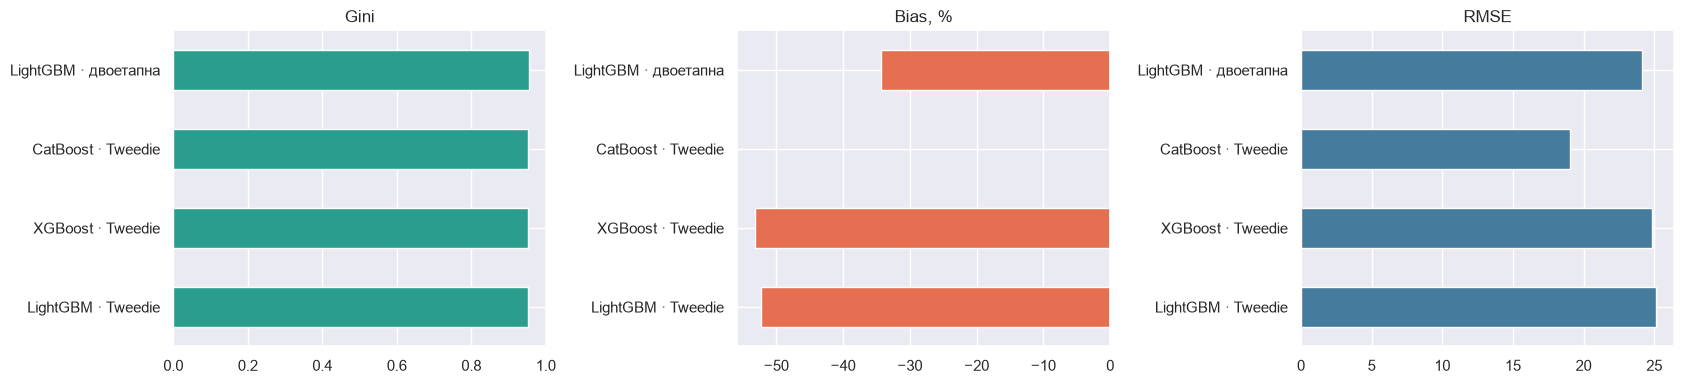

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, color in zip(axes, ["Gini", "Bias, %", "RMSE"], ["#2a9d8f", "#e76f51", "#457b9d"]):
    comparison[col].plot(kind="barh", ax=ax, color=color)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 3. Висновки по порівнянню

**Ранжування в усіх моделей однакове.** Gini 0,951–0,954, Top-5% share 0,907–0,911. За здатністю ставити платників угору обрати модель неможливо.

**Різниця — у сумарній виручці.**

| Модель | Bias, % | WAPE по каналах, % | RMSE |
|---|---|---|---|
| LightGBM · Tweedie | −52,4 | 52,4 | 25,1 |
| XGBoost · Tweedie | −53,2 | 53,2 | 24,9 |
| LightGBM · двоетапна | −34,4 | 34,4 | 24,2 |
| **CatBoost · Tweedie** | **−0,01** | **10,6** | **19,0** |

LightGBM та XGBoost занижують виручку приблизно вдвічі, двоетапна — на третину. **CatBoost майже точно попадає в сумарну виручку** (−0,01%), а його WAPE по каналах (10,6%) кращий навіть за простий baseline «ARPU каналу» з `02_modeling` (18,1%). Його RMSE також найменший, а це означає, що він набагато менше помиляється на великих платниках.

**Ціна.** CatBoost навчається 105 с проти 6,5 с у LightGBM (на ≈970 тис. рядків train), тобто приблизно в 16 разів довше. Для щоденного оновлення прогнозу це прийнятно.

**Чому так?** Я цього не перевіряв. Можливі причини: CatBoost інакше обробляє категоріальні ознаки та інакше оцінює значення в листах дерев, і тому краще передбачає великі суми. Це лише гіпотеза.

**Фінальна модель — CatBoost з Tweedie (`ρ = 1,5`)**, бо серед усіх перевірених вона єдина дає достовірну сумарну виручку по каналах, а ранжує так само добре, як і інші.

In [8]:
Path("../models").mkdir(exist_ok=True)
cat.save_model("../models/catboost_tweedie.cbm")
print("Збережено: models/catboost_tweedie.cbm")

Збережено: models/catboost_tweedie.cbm


## 4. Підсумок проєкту

**Що зроблено**
- Очистив дані (15% дублікатів у `params`), зібрав ознаки з реєстрації та першого дня життя користувача.
- Розбив дані за часом на train / valid / test, щоб модель не бачила майбутнього.
- Порівняв модель з baseline-ами («усім 0», «ARPU каналу», «день 1 = тиждень»). Саме так видно, чи справді модель щось додає.
- Порівняв двоетапну модель з однією Tweedie-моделлю в трьох бібліотеках.

**Головні результати (test, останні ≈3 тижні)**
- Моделі ранжують користувачів значно краще за baseline «день 1 = тиждень»: Gini 0,95 проти 0,81.
- Серед користувачів без оплат у день 1 (платників 0,57%) Gini — 0,76–0,77. Тобто модель справді знаходить майбутніх платників.
- LightGBM і XGBoost з Tweedie занижують сумарну виручку більш ніж наполовину. **CatBoost з Tweedie практично не має зсуву (−0,01%), а WAPE по каналах — 10,6%.**

**Обмеження**
- **Домінує день 1.** 36,6% виручки відомо вже після першого дня, тому метрики без порівняння з baseline «день 1 = тиждень» створюють завищене враження про якість.
- **«Кити».** Топ-1% платників дають 30% виручки. Прогноз для окремої людини залишається шумним, а надійні прогнози — це суми по когортах.
- **Один тестовий період і одне зерно.** Результат отримано на ≈3 тижнях test і з одним `random_state`. Тому майже нульовий bias CatBoost (−0,01%) може бути частково випадковістю, а не стабільною властивістю.
- **Без підбору гіперпараметрів.** Для CatBoost `ρ = 1,5` і решту параметрів я не підбирав.
- **Аномалії в даних.** 0,23% користувачів мають оплати у день 1 більші за `revenue_7d`; я залишив їх як є.
- **Нові канали.** Користувачі з новими значеннями `traffic_group_id`, яких не було в train, потраплять в окрему категорію без історії.

**Що можна зробити далі**
1. Підібрати `ρ` і гіперпараметри CatBoost, повторити на кількох періодах і кількох `random_state`, щоб оцінити стабільність зсуву.
2. Спробувати виправити зсув LightGBM масштабуванням прогнозу за valid.
3. Додати інтервали прогнозу (квантильна регресія): маркетингу корисніший діапазон, ніж одне число.
4. Розгорнути модель як FastAPI-сервіс і щодня рахувати прогноз по когортах.

## 5. Висновки для маркетингу

**Що дає модель**
- **Прогноз на 6 днів раніше.** Вже після першої доби можна оцінити тижневу виручку кожного каналу. На test (≈3 тижні, 322 тис. користувачів) CatBoost помиляється на сумарній виручці каналів на 10,6%, а простий «ARPU каналу» — на 18,1%. Виграш помірний, тож якщо структура трафіку стабільна, проста середня теж працює непогано.
- **Прогнози для груп, а не для окремих людей.** Топ-1% платників дають 30% виручки, тому для окремого користувача прогноз шумний. Помилку 10,6% я рахував по каналах за весь тестовий період; для щоденних або малих когорт вона буде більшою, і цього я не вимірював.
- **Користувачі без оплат у день 1** (98,6% test, платників серед них 0,57%). Модель упорядковує їх добре (Gini 0,77), а топ-5% за прогнозом містять 58% виручки цієї групи. Це можна використати для таргетування утримання, але ефект таких дій я не перевіряв.

**Що кажуть дані про канали**
- Тип трафіку 2 приносить $1,46 на користувача проти $0,86 і $0,96 у типів 1 і 3, платників там більше (2,7% проти 1,7% і 1,6%).
- Desktop і tablet платять не частіше за mobile, але платник витрачає більше (≈$74–75 проти $50).
- Найсильніші ознаки в моделі — активність у першу добу (кількість 6-годинних інтервалів з візитами, візити, оплати). За нею вже видно, чи прийшла «якісна» когорта.

**Чого модель не показує**
- **Причинності.** Вища виручка каналу 2 не означає, що збільшення його бюджету дасть таку саму виручку на кожного нового користувача. Можливо, він привертає інші країни чи пристрої; цього я не відокремлював.
- **Прибутковості.** У даних немає вартості залучення, а виручка за 7 днів не показує довшу цінність користувача.
- **Невизначеності.** Модель дає одне число, без діапазону.
- **Порядку каналів.** Я перевіряв точність сумарної виручки по каналах, але не те, чи правильно модель упорядковує канали між собою. Це треба перевірити, перш ніж порівнювати кампанії.
- **Стабільності в часі.** Результат отримано на одному тестовому періоді та з одним `random_state`.

**Як це застосувати**
1. Після першої доби прогнозувати виручку кожного каналу й ділити на витрати на залучення для ранньої оцінки окупності.
2. Раз на тиждень порівнювати прогноз із фактом і стежити за зсувом; перенавчати модель, коли помилка зростає.